# 04. Quantitative Evaluation Against PhysioNet Annotations

This notebook evaluates the detector's accuracy against expert cardiologist annotations using standard ANSI/AAMI EC57 tolerance-matching criteria.

### Evaluation Metrics:
- **True Positives (TP)**: Detected peaks that match a reference beat within $\pm 150$ ms.
- **False Positives (FP)**: Detected peaks with no corresponding reference beat.
- **False Negatives (FN)**: Reference beats missed by the detector.
- **Sensitivity (Recall)**: $Se = \frac{TP}{TP + FN}$
- **Positive Predictive Value (Precision)**: $PPV = \frac{TP}{TP + FP}$
- **$F_1$ Score**: $F_1 = 2 \times \frac{Se \times PPV}{Se + PPV}$

In [1]:
%matplotlib inline
import sys
from pathlib import Path
project_root = Path('..').resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
from src.data_loader import load_record
from src.preprocessing import preprocess_ecg
from src.peak_detection import detect_r_peaks
from src.evaluation import evaluate_detection, print_evaluation_summary
from src import config

## 1. Run Pipeline and Compute Quantitative Evaluation

In [2]:
ecg = load_record('100')
clean_ecg = preprocess_ecg(ecg.signal, ecg.sampling_frequency)
peaks = detect_r_peaks(clean_ecg, ecg.sampling_frequency)

result = evaluate_detection(
    detected_samples=peaks,
    reference_samples=ecg.beat_samples,
    fs=ecg.sampling_frequency,
    tolerance_sec=0.150,
    record_name='100'
)
print_evaluation_summary(result)

-------------------------------------------------------
  Evaluation — Record 100
-------------------------------------------------------
  Tolerance          : ±150 ms
  Reference beats    : 2,273
  Detected beats     : 2,265
  True Positives     : 2,265
  False Positives    : 0
  False Negatives    : 8
  Sensitivity (Se)   : 0.9965  (99.65%)
  PPV (Precision)    : 1.0000  (100.00%)
  F1 Score           : 0.9982  (99.82%)
-------------------------------------------------------


## 2. Metric Visualizations (TP, FP, FN breakdown)

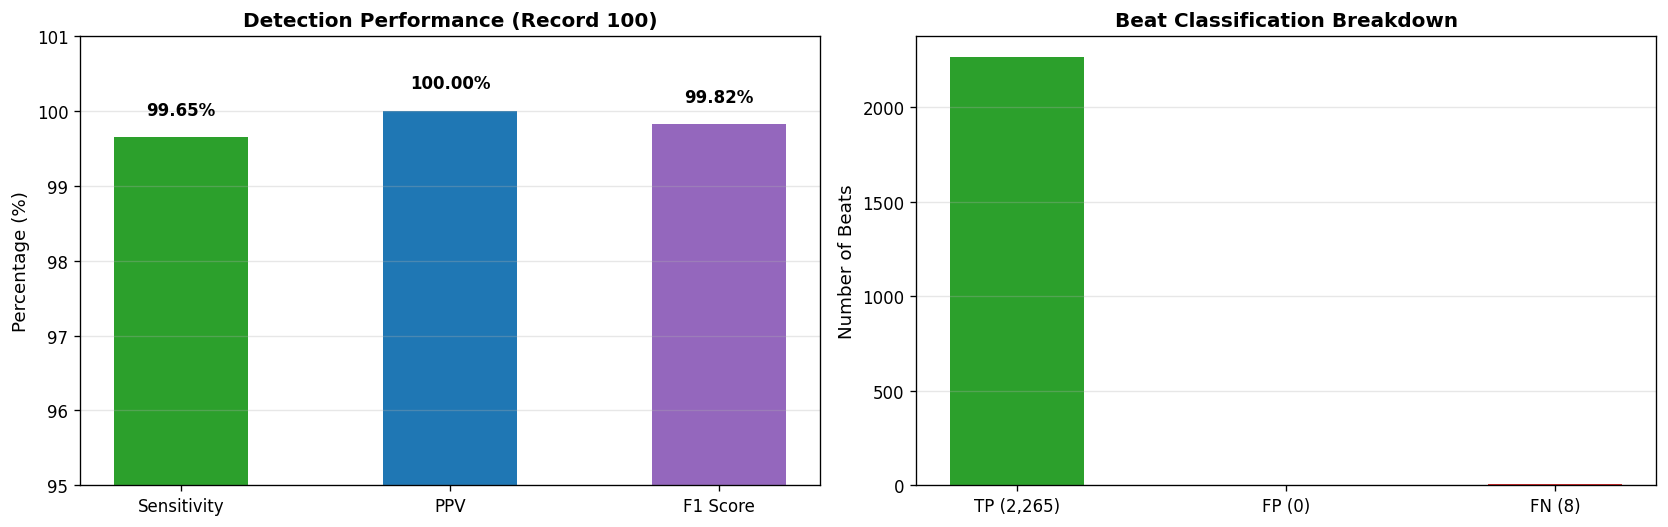

In [3]:
metrics = ['Sensitivity', 'PPV', 'F1 Score']
values = [result.sensitivity * 100, result.ppv * 100, result.f1 * 100]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), dpi=120)

# Bar chart of percentages
bars = ax1.bar(metrics, values, color=['#2ca02c', '#1f77b4', '#9467bd'], width=0.5)
ax1.set_ylim(95, 101)
ax1.set_ylabel('Percentage (%)', fontsize=11)
ax1.set_title('Detection Performance (Record 100)', fontweight='bold')
ax1.grid(True, axis='y', alpha=0.3)
for bar in bars:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, y + 0.3, f'{y:.2f}%', ha='center', fontweight='bold')

# Classification counts
counts = [result.true_positives, result.false_positives, result.false_negatives]
labels = [f'TP ({result.true_positives:,})', f'FP ({result.false_positives})', f'FN ({result.false_negatives})']
colors = ['#2ca02c', '#ff7f0e', '#d62728']
ax2.bar(labels, counts, color=colors, width=0.5)
ax2.set_title('Beat Classification Breakdown', fontweight='bold')
ax2.set_ylabel('Number of Beats', fontsize=11)
ax2.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 3. High-Resolution Visual Inspection of Detections vs Ground Truth
Overlays detected peaks (circles) against reference annotations (vertical crosses).

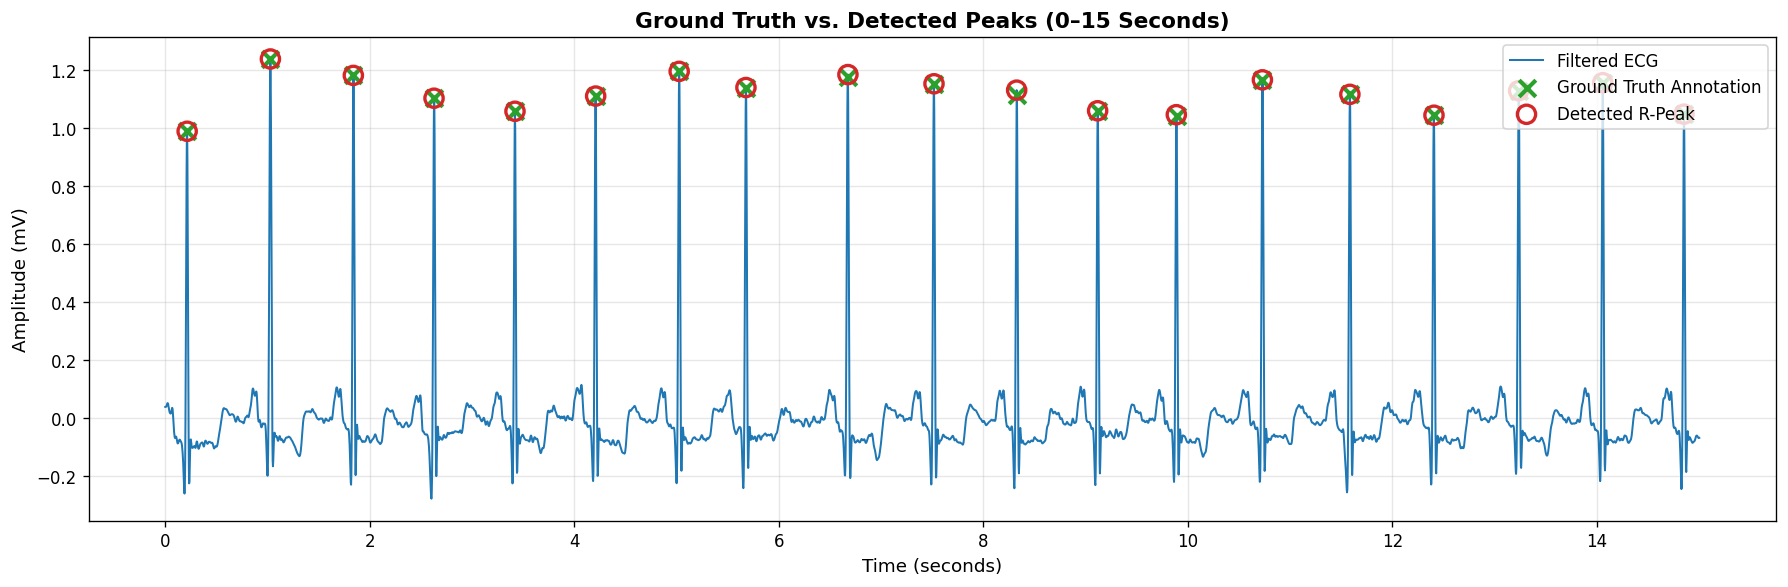

In [4]:
t_limit = 15.0
mask = ecg.time <= t_limit
t_plot = ecg.time[mask]
sig_plot = clean_ecg[mask]

# Detected peaks in slice
det_in_mask = peaks[peaks < int(t_limit * ecg.sampling_frequency)]
det_times = det_in_mask / ecg.sampling_frequency
det_amps = clean_ecg[det_in_mask]

# Ground truth beats in slice
ref_in_mask = ecg.beat_samples[ecg.beat_samples < int(t_limit * ecg.sampling_frequency)]
ref_times = ref_in_mask / ecg.sampling_frequency
ref_amps = clean_ecg[ref_in_mask]

plt.figure(figsize=(15, 5), dpi=120)
plt.plot(t_plot, sig_plot, color='#1f77b4', lw=1.2, label='Filtered ECG')
plt.scatter(ref_times, ref_amps, color='#2ca02c', s=100, marker='x', lw=2.5, zorder=4, label='Ground Truth Annotation')
plt.scatter(det_times, det_amps, facecolors='none', edgecolors='#d62728', s=120, lw=2, zorder=5, label='Detected R-Peak')
plt.title('Ground Truth vs. Detected Peaks (0–15 Seconds)', fontsize=13, fontweight='bold')
plt.xlabel('Time (seconds)', fontsize=11)
plt.ylabel('Amplitude (mV)', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()